# Problem 4 · A brick column cooled by air on one side

**simple_CFD · Introduction to Computational Fluid Dynamics with the Finite Difference Method**

> *A large industrial furnace is supported on a long column of fireclay brick, 1 m by 1 m on a side. During steady operation, three surfaces of the column are kept at 500 K, while the remaining surface is exposed to an air stream with $T_\infty = 300$ K and $h = 10$ W/(m²·K). Using a grid with $\Delta x = \Delta y = 0.25$ m, determine the two-dimensional temperature distribution in the column and the heat rate to the air stream per unit length of column.*
> (Adapted from Incropera et al., *Fundamentals of Heat and Mass Transfer*, Example 4.3.)

Problem 3 had only fixed-temperature edges. Here one side **loses heat by convection**, so its temperature is unknown and we need a new kind of node equation. We derive all node equations with the **energy balance method**, and use **symmetry** to halve the work. As always, we follow **the 7 pillars of CFD**:

| Pillar | What we do here |
|:-:|---|
| 1 · Geometry | the column cross-section and its boundary conditions |
| 2 · Grid | a 5 × 5 grid; symmetry leaves 8 unknown temperatures |
| 3 · Physics | the Laplace equation with a convection boundary condition |
| 4 · Numerical scheme | energy balances on small control volumes → 8 node equations |
| 5 · Solution setup | Gaussian elimination (direct) and Gauss–Seidel (iterative) |
| 6 · Compute | solve the 8 equations both ways |
| 7 · Post-processing | temperature map, heat rate to the air, energy check, grid refinement |

> **Plain Python only.** All numerical work uses ordinary Python lists and `for` loops, so you can follow every number. The only import used in the calculations is `math` (part of Python itself). The figures are drawn by `plots.py` (with matplotlib); you do not need to open it to follow the method.

In [1]:
import math     # built into Python: sin, pi (only for the over-relaxation factor)
import plots    # our drawing helpers (plots.py)

---
## Pillar 1 · The physical problem and its geometry

The column is long, and nothing changes along its length, so the temperature only varies over the **cross-section**: a two-dimensional problem in $x$ and $y$. Heat flows from the three hot sides (500 K) through the brick towards the bottom side, where the air carries it away.

**Assumptions:** steady state; two-dimensional conduction; no heat generation; constant thermal conductivity (fireclay brick, $k \approx 1$ W/(m·K) at about 478 K); constant convection coefficient; radiation neglected.

In [2]:
# ---- geometry and grid ---------------------------------------------------
W = 1.0          # width (and height) of the square cross-section [m]
dx = 0.25        # grid spacing, dx = dy                           [m]

# ---- material -------------------------------------------------------------
k = 1.0          # thermal conductivity of fireclay brick          [W/(m K)]

# ---- boundary conditions ---------------------------------------------------
T_s = 500.0      # temperature of the top, left and right surfaces [K]
T_inf = 300.0    # temperature of the air stream                   [K]
h = 10.0         # convection coefficient at the bottom surface    [W/(m^2 K)]

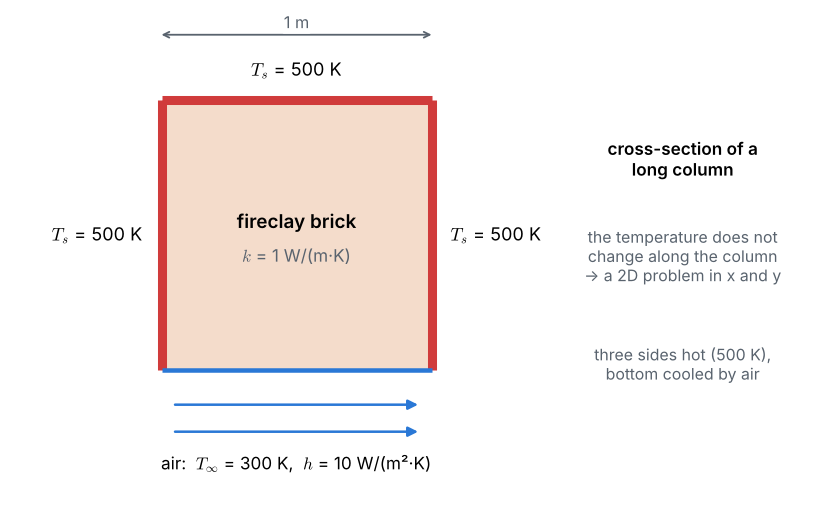

In [3]:
plots.schematic(W, T_s, T_inf, h, k)

---
## Pillar 2 · The grid, and how symmetry halves the work

With $\Delta x = \Delta y = 0.25$ m the cross-section has $5 \times 5 = 25$ nodes $(i, j)$, with $i$ along $x$ and $j$ along $y$, and $j = 0$ on the bottom surface.

* Nodes on the **top, left and right** surfaces are known: 500 K. That includes the two bottom corners, which belong to the hot side walls.
* The three nodes **on the bottom surface** are **unknown**: their temperature depends on how much heat the air removes.
* The 9 nodes **inside** are unknown.

That makes 12 unknowns. But the geometry and the boundary conditions are **symmetric** about the vertical centre line $x = 0.5$ m, so the temperature field is symmetric too: the column $i = 3$ has exactly the same temperatures as the column $i = 1$. Only **8 unknowns** remain, numbered as in the figure: odd numbers in the column $i = 1$, even numbers on the symmetry line $i = 2$.

In [4]:
N = round(W / dx)                                   # number of intervals per side

NODES = {1: (1, 3), 2: (2, 3), 3: (1, 2), 4: (2, 2),
         5: (1, 1), 6: (2, 1), 7: (1, 0), 8: (2, 0)}  # node number -> (i, j)
number_of = {ij: n for n, ij in NODES.items()}       # (i, j) -> node number


def mirror(i, j):
    """Use symmetry: column i = 3 has the same temperatures as column i = 1."""
    return (N - i, j) if i > N // 2 else (i, j)


# print the grid row by row, top row first
for j in range(N, -1, -1):
    row = []
    for i in range(N + 1):
        ij = mirror(i, j)
        if ij in number_of:
            name = f"T{number_of[ij]}" + ("'" if ij != (i, j) else " ")
            row.append(f"{name:>6s}")
        else:
            row.append(f"{T_s:6.0f}")
    print(f"j = {j}: " + "".join(row))
print("\nT1' means 'equal to T1 by symmetry'")

j = 4:    500   500   500   500   500
j = 3:    500   T1    T2    T1'   500
j = 2:    500   T3    T4    T3'   500
j = 1:    500   T5    T6    T5'   500
j = 0:    500   T7    T8    T7'   500

T1' means 'equal to T1 by symmetry'


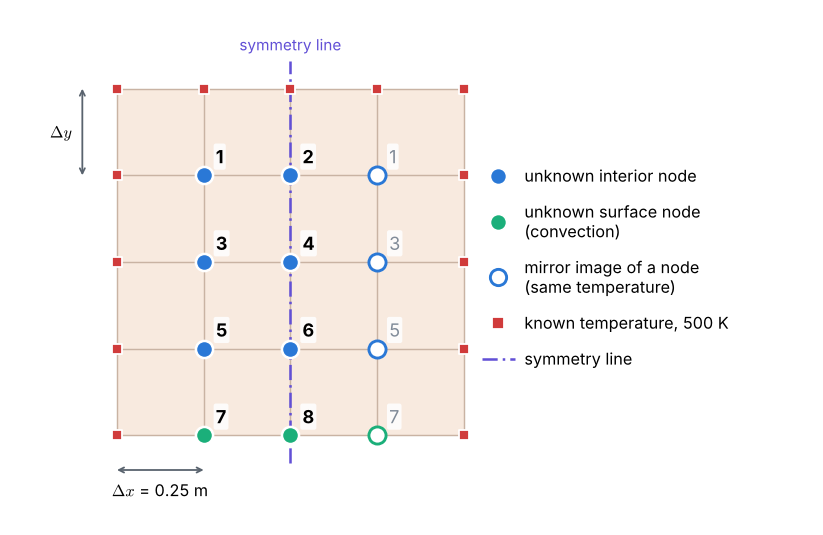

In [5]:
plots.grid(W, dx)

---
## Pillar 3 · Physics: the governing equation and boundary conditions

Inside the brick, steady two-dimensional conduction without heat generation gives the **Laplace equation**, as in Problem 3:

$$\frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2} = 0.$$

The boundary conditions are of two kinds:

| surface | condition | type |
|---|---|---|
| top, left, right | $T = T_s = 500$ K | Dirichlet (value known) |
| bottom ($y = 0$) | $k\,\dfrac{\partial T}{\partial y} = h\,(T - T_\infty)$ | Robin / convection: the heat conducted to the surface is carried away by the air |

The convection condition does not fix the surface temperature; it links the temperature to its slope. How strongly the air cools the surface compared with how easily the brick conducts is measured by the **Biot number** of a grid cell:

$$Bi = \frac{h\,\Delta x}{k} = \frac{10 \times 0.25}{1} = 2.5.$$

There is no simple exact solution for this problem, so we will check our answer by refining the grid.

---
## Pillar 4 · Numerical scheme: the energy balance method

In Problems 1 and 3 we replaced derivatives by finite differences from Taylor series. An equivalent and very physical way is the **energy balance method**: put a small **control volume** around every node and require that, in steady state, **the heat flowing into it from all sides adds up to zero**. Between two neighbouring nodes, Fourier's law gives the heat flow per unit length of column

$$q = k \times (\text{face length}) \times \frac{T_{neighbour} - T_P}{\text{distance}}.$$

The method shines at boundaries: we simply include the convection to the air in the balance.

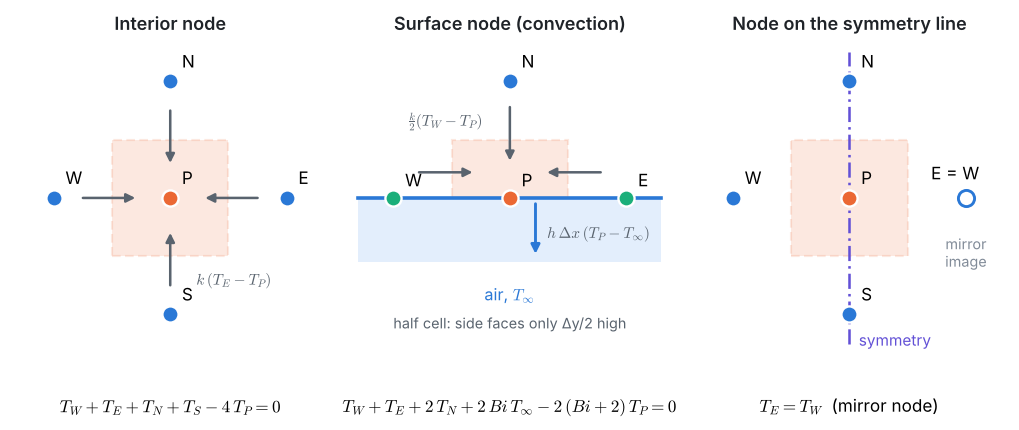

In [6]:
plots.control_volumes()

**Interior node.** The control volume is a full $\Delta x \times \Delta y$ square. With $\Delta x = \Delta y$, every face is $\Delta x$ long:

$$k\,\Delta x\,\frac{T_E - T_P}{\Delta x} + k\,\Delta x\,\frac{T_W - T_P}{\Delta x} + k\,\Delta x\,\frac{T_N - T_P}{\Delta x} + k\,\Delta x\,\frac{T_S - T_P}{\Delta x} = 0
\quad\Longrightarrow\quad T_E + T_W + T_N + T_S - 4\,T_P = 0.$$

This is the five-point formula of Problem 3 again.

**Surface node with convection.** The control volume is only **half a cell** high ($\Delta y/2$), because the node sits on the surface. Its side faces are $\Delta y/2$ long, its top face is $\Delta x$ long, and its bottom face, $\Delta x$ long, touches the air:

$$k\,\frac{\Delta y}{2}\,\frac{T_W - T_P}{\Delta x} + k\,\frac{\Delta y}{2}\,\frac{T_E - T_P}{\Delta x} + k\,\Delta x\,\frac{T_N - T_P}{\Delta y} + h\,\Delta x\,(T_\infty - T_P) = 0.$$

Multiplying by $2/k$ (with $\Delta x = \Delta y$) and using $Bi = h\Delta x/k$:

$$T_W + T_E + 2\,T_N + 2\,Bi\,T_\infty - 2\,(Bi + 2)\,T_P = 0.$$

**Node on the symmetry line.** Same equations, but its right-hand neighbour is the mirror image of its left-hand one, so that temperature appears **twice**.

The function below returns the weights of the neighbours, the coefficient of $T_P$ and the constant term for any node:

In [7]:
def node_equation(i, j, dx):
    """Energy balance at node (i, j): sum(weight * T_neighbour) + diagonal * T_P + constant = 0."""
    Bi = h * dx / k
    if j == 0:                  # bottom surface: half control volume with convection
        weights = {(i - 1, j): 1.0, (i + 1, j): 1.0, (i, j + 1): 2.0}
        diagonal = -2.0 * (Bi + 2.0)
        constant = 2.0 * Bi * T_inf
    else:                       # interior node: full control volume
        weights = {(i - 1, j): 1.0, (i + 1, j): 1.0, (i, j + 1): 1.0, (i, j - 1): 1.0}
        diagonal = -4.0
        constant = 0.0
    return weights, diagonal, constant

Now **assemble** the 8 equations into a linear system $A\,\mathbf{T} = \mathbf{b}$: an unknown neighbour (after applying symmetry) adds its weight to the matrix $A$, a known 500 K neighbour moves to the right-hand side $\mathbf{b}$, and so does the constant term.

In [8]:
n_unknowns = len(NODES)
A = [[0.0] * n_unknowns for _ in range(n_unknowns)]
b = [0.0] * n_unknowns

for n, (i, j) in NODES.items():
    row = n - 1
    weights, diagonal, constant = node_equation(i, j, dx)
    A[row][row] += diagonal
    b[row] -= constant
    for neighbour, weight in weights.items():
        neighbour = mirror(*neighbour)                 # symmetry: column 3 -> column 1
        if neighbour in number_of:                     # unknown: stays on the left
            A[row][number_of[neighbour] - 1] += weight
        else:                                          # known surface at 500 K: to the right
            b[row] -= weight * T_s

print(f"Bi = h dx / k = {h * dx / k}\n")
for row in range(n_unknowns):
    terms = "  ".join(f"{A[row][c]:+g}·T{c + 1}" for c in range(n_unknowns) if A[row][c] != 0)
    print(f"node {row + 1}:  {terms:38s} = {b[row]:7.0f}")

Bi = h dx / k = 2.5

node 1:  -4·T1  +1·T2  +1·T3                    =   -1000
node 2:  +2·T1  -4·T2  +1·T4                    =    -500
node 3:  +1·T1  -4·T3  +1·T4  +1·T5             =    -500
node 4:  +1·T2  +2·T3  -4·T4  +1·T6             =       0
node 5:  +1·T3  -4·T5  +1·T6  +1·T7             =    -500
node 6:  +1·T4  +2·T5  -4·T6  +1·T8             =       0
node 7:  +2·T5  -9·T7  +1·T8                    =   -2000
node 8:  +2·T6  +2·T7  -9·T8                    =   -1500


Written out, these are the eight node equations:

| node | kind | equation |
|:-:|---|---|
| 1 | interior, next to two hot walls | $-4T_1 + T_2 + T_3 = -1000$ |
| 2 | interior, on the symmetry line | $2T_1 - 4T_2 + T_4 = -500$ |
| 3 | interior, next to the left wall | $T_1 - 4T_3 + T_4 + T_5 = -500$ |
| 4 | interior, on the symmetry line | $T_2 + 2T_3 - 4T_4 + T_6 = 0$ |
| 5 | interior, next to the left wall | $T_3 - 4T_5 + T_6 + T_7 = -500$ |
| 6 | interior, on the symmetry line | $T_4 + 2T_5 - 4T_6 + T_8 = 0$ |
| 7 | surface, next to the corner | $2T_5 - 9T_7 + T_8 = -2000$ |
| 8 | surface, on the symmetry line | $2T_6 + 2T_7 - 9T_8 = -1500$ |

---
## Pillar 5 · Solution setup

We use the same two algorithms as in Problem 3:

* **Gaussian elimination** (direct): forward elimination to an upper-triangular matrix, then back substitution. We print the augmented matrix $[A\,|\,\mathbf{b}]$ before and after the elimination.
* **Gauss–Seidel** (iterative): solve each equation for its own unknown and sweep repeatedly, always with the newest values, starting from a guess of 400 K everywhere.

In [9]:
def show(Ab, title):
    """Print an augmented matrix [A | b]."""
    print(title)
    for row in Ab:
        print("  [" + "".join(f"{v:8.3f}" for v in row[:-1]) + "  |" + f"{row[-1]:10.2f} ]")
    print()


def gaussian_elimination(A, b, verbose=False):
    """Solve A x = b by forward elimination and back substitution."""
    n = len(b)
    Ab = [A[r][:] + [b[r]] for r in range(n)]          # augmented matrix [A | b]
    if verbose:
        show(Ab, "start:")

    # forward elimination: create zeros below the diagonal, column by column
    for p in range(n - 1):                             # p = pivot row
        for r in range(p + 1, n):                      # every row below the pivot
            factor = Ab[r][p] / Ab[p][p]
            for c in range(p, n + 1):
                Ab[r][c] -= factor * Ab[p][c]
    if verbose:
        show(Ab, "after forward elimination (upper triangular):")

    # back substitution: from the last row up to the first
    x = [0.0] * n
    for r in range(n - 1, -1, -1):
        total = Ab[r][n]
        for c in range(r + 1, n):
            total -= Ab[r][c] * x[c]
        x[r] = total / Ab[r][r]
    return x

In [10]:
def gauss_seidel(A, b, T_start, tol=1e-4, max_iter=1000):
    """Solve A x = b by Gauss-Seidel iteration; also return every iterate."""
    T = T_start[:]
    history = [T[:]]                                   # the guess, then every iteration
    changes = []
    for iteration in range(max_iter):
        largest_change = 0.0
        for row in range(len(b)):
            total = b[row]
            for c in range(len(b)):
                if c != row:
                    total -= A[row][c] * T[c]
            new_value = total / A[row][row]
            largest_change = max(largest_change, abs(new_value - T[row]))
            T[row] = new_value                         # use the new value immediately
        history.append(T[:])
        changes.append(largest_change)
        if largest_change < tol:
            break
    return T, history, changes

---
## Pillar 6 · Compute

### Gaussian elimination

In [11]:
T = gaussian_elimination(A, b, verbose=True)

for n in NODES:
    print(f"T{n} = {T[n - 1]:.2f} K")

start:
  [  -4.000   1.000   1.000   0.000   0.000   0.000   0.000   0.000  |  -1000.00 ]
  [   2.000  -4.000   0.000   1.000   0.000   0.000   0.000   0.000  |   -500.00 ]
  [   1.000   0.000  -4.000   1.000   1.000   0.000   0.000   0.000  |   -500.00 ]
  [   0.000   1.000   2.000  -4.000   0.000   1.000   0.000   0.000  |      0.00 ]
  [   0.000   0.000   1.000   0.000  -4.000   1.000   1.000   0.000  |   -500.00 ]
  [   0.000   0.000   0.000   1.000   2.000  -4.000   0.000   1.000  |      0.00 ]
  [   0.000   0.000   0.000   0.000   2.000   0.000  -9.000   1.000  |  -2000.00 ]
  [   0.000   0.000   0.000   0.000   0.000   2.000   2.000  -9.000  |  -1500.00 ]

after forward elimination (upper triangular):
  [  -4.000   1.000   1.000   0.000   0.000   0.000   0.000   0.000  |  -1000.00 ]
  [   0.000  -3.500   0.500   1.000   0.000   0.000   0.000   0.000  |  -1000.00 ]
  [   0.000   0.000  -3.714   1.071   1.000   0.000   0.000   0.000  |   -821.43 ]
  [   0.000   0.000   0.000  -3.0

### Gauss–Seidel

In [12]:
tol = 1e-4
T_gs, history, changes = gauss_seidel(A, b, [400.0] * n_unknowns, tol)

print(f"converged after {len(changes)} iterations\n")
print(" iter " + "".join(f"     T{n}" for n in NODES))
for it in (0, 1, 2, 3, 5, 10, len(changes)):
    print(f"{it:4d}  " + "".join(f"{v:7.2f}" for v in history[it]))
print(f"\nlargest difference from Gaussian elimination: "
      f"{max(abs(p - q) for p, q in zip(T, T_gs)):.1e} K")

converged after 20 iterations

 iter      T1     T2     T3     T4     T5     T6     T7     T8
   0   400.00 400.00 400.00 400.00 400.00 400.00 400.00 400.00
   1   450.00 450.00 437.50 431.25 434.38 425.00 363.19 341.82
   2   471.88 468.75 459.38 453.12 436.89 417.18 357.29 338.77
   3   482.03 479.30 468.01 458.13 435.62 417.03 356.67 338.60
   5   488.27 484.15 471.08 460.99 436.36 418.12 356.83 338.88
  10   489.26 485.11 472.02 461.96 436.92 418.71 356.99 339.04
  20   489.30 485.15 472.06 462.01 436.95 418.74 356.99 339.05

largest difference from Gaussian elimination: 1.0e-04 K


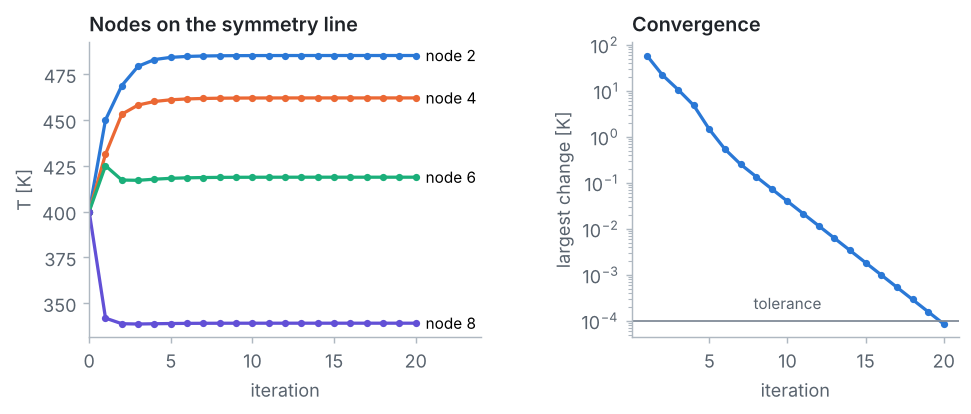

In [13]:
plots.iterations(history, changes, tol)

Both methods agree. They also agree with the published solution of this example (Incropera et al., Example 4.3): $T_1 = 489.30$, $T_2 = 485.15$, $T_3 = 472.07$, $T_4 = 462.01$, $T_5 = 436.95$, $T_6 = 418.74$, $T_7 = 356.99$, $T_8 = 339.05$ K.

---
## Pillar 7 · Post-processing

### The temperature distribution

Mirroring the 8 values across the symmetry line gives the whole cross-section:

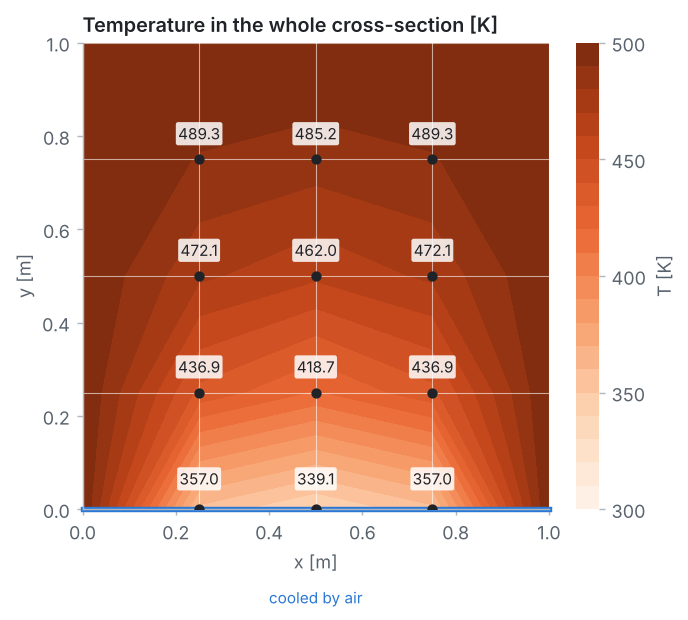

In [14]:
plots.temperature_map(T, T_s, T_inf, W, dx)

### Heat rate to the air stream

The bottom surface is split into pieces, one for each surface node: the two corners (part of the 500 K walls) each own $\Delta x/2$, node 8 on the symmetry line owns $\Delta x$, and nodes 7 and its mirror image each own $\Delta x$. Adding up Newton's law of cooling, $q = h \times \text{length} \times (T - T_\infty)$, and using symmetry (twice the left half):

$$q' = 2h\left[\frac{\Delta x}{2}(T_s - T_\infty) + \Delta x\,(T_7 - T_\infty) + \frac{\Delta x}{2}(T_8 - T_\infty)\right].$$

In [15]:
T7, T8 = T[6], T[7]
q_corners = 2 * h * (dx / 2) * (T_s - T_inf)
q_nodes = 2 * h * (dx * (T7 - T_inf) + (dx / 2) * (T8 - T_inf))
q_air = q_corners + q_nodes

print(f"from the two corners (at 500 K): {q_corners:6.1f} W/m")
print(f"from nodes 7, 8 and 7':          {q_nodes:6.1f} W/m")
print(f"heat rate to the air:     q' = {q_air:6.1f} W/m")

from the two corners (at 500 K):  500.0 W/m
from nodes 7, 8 and 7':           382.6 W/m
heat rate to the air:     q' =  882.6 W/m


### Energy check: heat in = heat out

Where does that heat come from? It enters the brick by conduction from the 500 K walls. The function below adds up, over the **whole** cross-section, the heat conducted from every known 500 K node into its unknown neighbours, and the heat convected from the unknown surface nodes to the air. It uses the same face lengths as the energy balances above (half faces next to the surface) and works for any grid with $N$ intervals.

In [16]:
def heat_flows(Tf, N):
    """Heat [W/m] conducted in from the hot walls and convected out by the unknown surface nodes."""
    dx = W / N
    unknown = lambda i, j: 0 < i < N and 0 <= j < N             # noqa: E731
    q_in = 0.0
    for j in range(N):
        for i in range(1, N):                                    # every unknown node P
            for ni, nj in ((i - 1, j), (i + 1, j), (i, j + 1), (i, j - 1)):
                if nj >= 0 and not unknown(ni, nj):              # a known 500 K neighbour
                    face = dx / 2 if (j == 0 and nj == 0) else dx
                    q_in += k * face * (Tf[nj][ni] - Tf[j][i]) / dx
    q_out = sum(h * dx * (Tf[0][i] - T_inf) for i in range(1, N))
    return q_in, q_out


# the full 5 x 5 field Tf[j][i] (row j = 0 is the bottom), with the mirror images
Tf = [[T_s] * (N + 1) for _ in range(N + 1)]
for n, (i, j) in NODES.items():
    Tf[j][i] = Tf[j][N - i] = T[n - 1]

q_in, q_out = heat_flows(Tf, N)
print(f"conducted in from the 500 K walls:   {q_in:7.2f} W/m")
print(f"convected out by nodes 7, 8 and 7':  {q_out:7.2f} W/m")
print(f"difference:                          {abs(q_in - q_out):7.2f} W/m")

conducted in from the 500 K walls:    382.60 W/m
convected out by nodes 7, 8 and 7':   382.60 W/m
difference:                             0.00 W/m


The two agree exactly: the energy balances of all control volumes add up to a balance for the whole column, so **the finite difference solution conserves energy**. The other 500 W/m reach the air through the two corners, which are part of the hot walls.

### Is the grid fine enough? A surprise

A grid of 0.25 m is very coarse. Let us solve the same column on finer grids. With thousands of unknowns we do not build the matrix; we apply the node equations directly on the grid and iterate with **successive over-relaxation (SOR)**, the accelerated Gauss–Seidel method of Problem 3. This solver works on the **full** cross-section, so it does not need symmetry.

In [17]:
def solve_column(N, tol=1e-6):
    """Temperatures Tf[j][i] in the column on a grid with N x N intervals, by SOR."""
    dx = W / N
    Bi = h * dx / k
    omega = 2.0 / (1.0 + math.sin(math.pi / N))         # over-relaxation factor
    Tf = [[T_s] * (N + 1) for _ in range(N + 1)]        # walls and top at 500 K ...
    for j in range(N):
        for i in range(1, N):
            Tf[j][i] = 400.0                             # ... and a guess for the unknowns

    for sweep in range(1, 100_000):
        largest_change = 0.0
        for j in range(N):
            for i in range(1, N):
                if j == 0:                               # surface node with convection
                    new = (Tf[0][i - 1] + Tf[0][i + 1] + 2 * Tf[1][i] + 2 * Bi * T_inf) / (2 * (Bi + 2))
                else:                                    # interior node
                    new = (Tf[j][i - 1] + Tf[j][i + 1] + Tf[j + 1][i] + Tf[j - 1][i]) / 4
                new = Tf[j][i] + omega * (new - Tf[j][i])
                largest_change = max(largest_change, abs(new - Tf[j][i]))
                Tf[j][i] = new
        if largest_change < tol:
            break
    return Tf, sweep


def heat_to_air(Tf, N):
    """q' [W/m]: the two corners (half a cell each, at 500 K) plus every unknown surface node."""
    dx = W / N
    return 2 * h * (dx / 2) * (T_s - T_inf) + sum(h * dx * (Tf[0][i] - T_inf) for i in range(1, N))

In [18]:
grids = [4, 8, 16, 32, 64, 128]
results = {}
print("   N   dx [m]   sweeps   T bottom centre [K]   q' [W/m]   of which corners   in - out")
for n_int in grids:
    Tf_n, sweeps = solve_column(n_int)
    results[n_int] = Tf_n
    q_in_n, q_out_n = heat_flows(Tf_n, n_int)
    corners = 2 * h * (W / n_int / 2) * (T_s - T_inf)
    print(f"{n_int:4d}  {W / n_int:7.4f}  {sweeps:6d}   {Tf_n[0][n_int // 2]:14.2f}        "
          f"{heat_to_air(Tf_n, n_int):8.1f}   {corners:12.1f}      {q_in_n - q_out_n:+.1e}")

   N   dx [m]   sweeps   T bottom centre [K]   q' [W/m]   of which corners   in - out
   4   0.2500      18           339.05           882.6          500.0      +1.9e-06
   8   0.1250      36           337.45           722.3          250.0      +8.8e-06
  16   0.0625      70           337.32           659.0          125.0      +2.4e-05
  32   0.0312     136           337.28           635.5           62.5      +5.0e-05


  64   0.0156     261           337.28           627.3           31.2      +1.1e-04


 128   0.0078     509           337.27           624.6           15.6      +1.8e-04


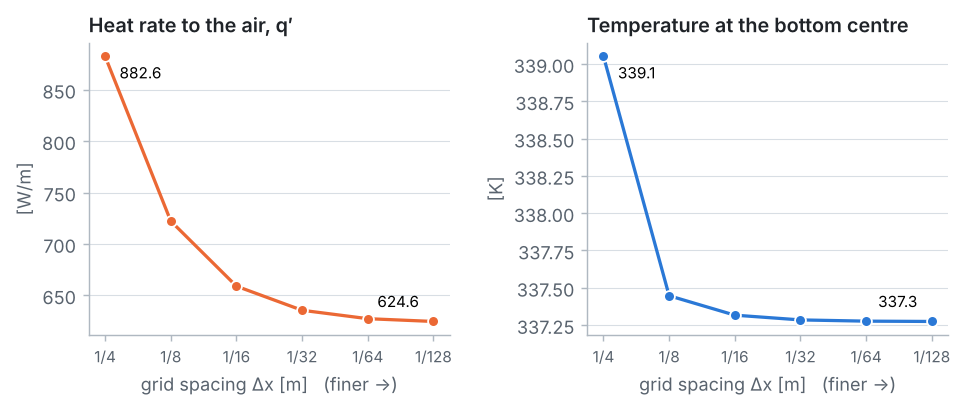

In [19]:
plots.refinement([W / n for n in grids], [heat_to_air(results[n], n) for n in grids],
                 [results[n][0][n // 2] for n in grids])

Two very different behaviours:

* **Temperatures converge fast.** The bottom-centre temperature changes from 339.1 K on the coarse grid to about 337.3 K on the finest grid, and most nodes move by less than 3 K. Only node 7, right next to the cooled corner, moves more (from 357.0 K to 348.4 K): the steep corner region again.
* **The heat rate does not.** It drops from 883 W/m to about 625 W/m: the coarse grid **overestimates the heat loss by about 40 %**. The culprit is the **corners**. On the coarse grid, each bottom corner, held at 500 K, is credited with half a cell, 0.125 m, of hot surface exposed to the air: together that is 500 W/m, more than half of the total. On finer grids this strip shrinks, and the true surface temperature next to the corner drops quickly from 500 K towards the air temperature.

Near a corner where a hot wall meets a cooled surface, the temperature changes very steeply, and a coarse grid cannot resolve it. This is why real CFD meshes are **refined near corners and walls**. Lesson: *a grid that is fine enough for the temperatures may not be fine enough for the heat flux.*

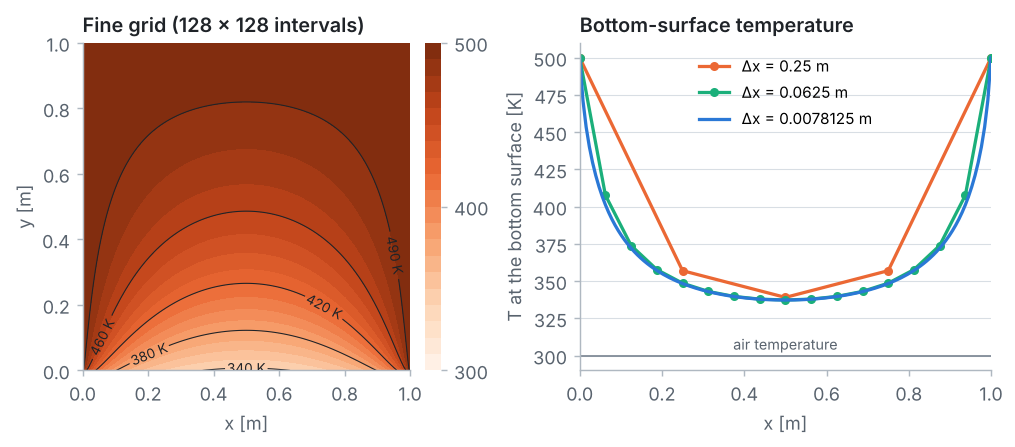

In [20]:
plots.fine_solution(results[128], W, T_inf, T_s, {n: results[n][0] for n in (4, 16, 128)})

On the right, the bottom-surface temperature on three grids: the coarse grid (dots) has the right shape in the middle, but only the fine grids show how quickly the surface cools next to the corners.

---
## Summary

* Node equations can be derived with **energy balances on control volumes**, which handle boundary conditions naturally.
* A **convection surface node** uses a half control volume: $T_W + T_E + 2T_N + 2\,Bi\,T_\infty - 2(Bi + 2)T_P = 0$, with $Bi = h\Delta x/k$.
* **Symmetry** reduced 12 unknowns to 8; nodes on the symmetry line see their mirror neighbour twice.
* Gaussian elimination and Gauss–Seidel give $T_1, \dots, T_8$ = 489.30, 485.15, 472.07, 462.01, 436.95, 418.74, 356.99, 339.05 K, and a heat rate to the air of **883 W/m** on this grid.
* The discrete solution conserves energy exactly, but **grid refinement** shows that the heat rate converges to about 625 W/m: coarse grids handle temperatures well and corner heat fluxes poorly.

## Try it yourself

1. Double the convection coefficient to $h = 20$ W/(m²·K). How do $T_8$ and $q'$ change? Why does $q'$ not double?
2. Solve the 12-unknown problem **without** using symmetry (`solve_column(4)` does exactly that). Check that you get the same temperatures.
3. In `solve_column`, set `omega = 1.0` (plain Gauss–Seidel) and solve with `N = 64`. How many more sweeps are needed?
4. Make the bottom surface **insulated** ($h = 0$). What temperature do you expect everywhere? Check it.
5. *Challenge:* the heat rate from the fine grids seems to approach a limit. Estimate it by extrapolating the values for `N = 32, 64, 128`.